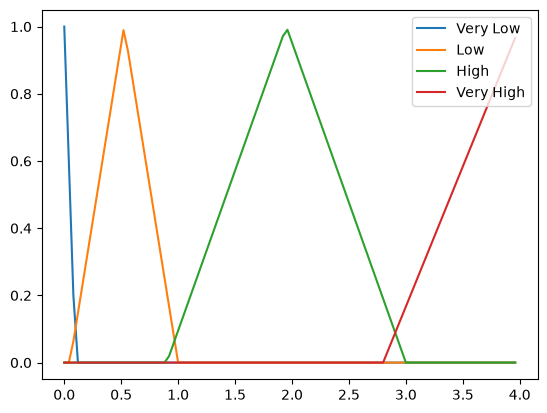

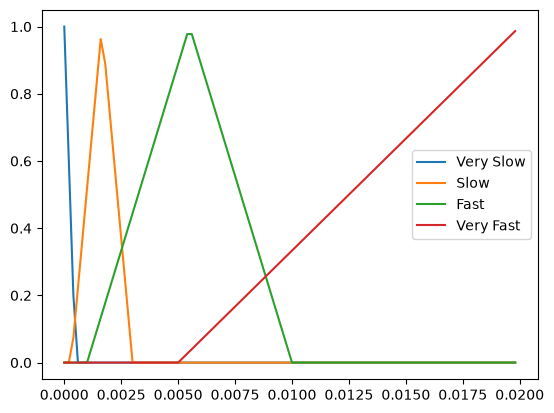

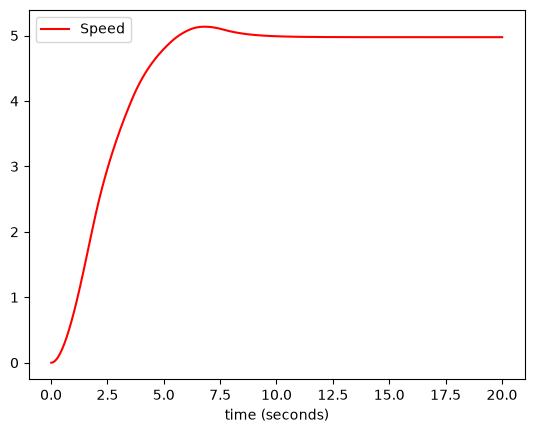

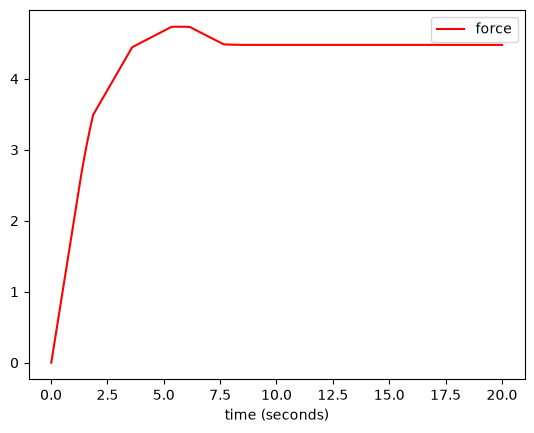

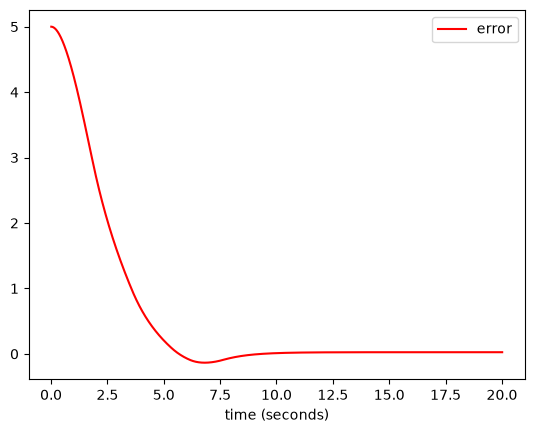

In [1]:
#
# fuzzy_speed_control.py
#

import arslabrobotics as ar

class FuzzySpeedController:

    def __init__(self):
        self.very_low = ar.fuzzy.Down("Very Low", 0, 0.1)
        self.low = ar.fuzzy.Triangle("Low", 0.05, 1.0)
        self.high = ar.fuzzy.Triangle("High", 0.9, 3.0)
        self.very_high = ar.fuzzy.Up("Very High", 2.8, 4.0)
        ar.fuzzy.plot_fuzzysets([self.very_low, self.low, self.high, self.very_high])

        self.very_slow = ar.fuzzy.Down("Very Slow", 0, 0.0005)
        self.slow = ar.fuzzy.Triangle("Slow", 0.0003, 0.003)
        self.fast = ar.fuzzy.Triangle("Fast", 0.001, 0.01)
        self.very_fast = ar.fuzzy.Up("Very Fast", 0.005, 0.02)
        ar.fuzzy.plot_fuzzysets([self.very_slow, self.slow, self.fast, self.very_fast])

        self.error = ar.fuzzy.Variable()
        self.accelerate = ar.fuzzy.Variable()

        self.r1 = self.error(self.very_low) >> self.accelerate(self.very_slow)
        self.r2 = self.error(self.low) >> self.accelerate(self.slow)
        self.r3 = self.error(self.high) >> self.accelerate(self.fast)
        self.r4 = self.error(self.very_high) >> self.accelerate(self.very_fast)

        self.engine = ar.fuzzy.FuzzyEngine()
        self.engine.use_mom()

        self.output = 0

    def evaluate(self, target, current):
        error = target - current
        sgn = 1
        if error < 0:
            error = - error
            sgn = -1
        self.error.set(error)
        self.engine.execute(self.r1, self.r2, self.r3, self.r4)
        acc = self.engine.get(self.accelerate)
        self.output += sgn * acc
        return self.output

spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

fpd = ar.data.DataPlotter()
fpd.set_x("time (seconds)")
fpd.add_y("force", "force")

epd = ar.data.DataPlotter()
epd.set_x("time (seconds)")
epd.add_y("error", "error")


fuzzy_ctrl = FuzzySpeedController()

cart = ar.system.Cart(1.0, 0.9)

target = 5.0

force = 0

t = ar.utils.Time(use_fake_time = True)
t.start()
while t.get() < 20:

    t.sleep(0.01)
    delta_t = t.elapsed()

    (p, v) = cart.evaluate(delta_t, force)
    
    spd.append_x(t.get())
    spd.append_y("speed", v)
    
    fpd.append_x(t.get())
    fpd.append_y("force", force)
    
    epd.append_x(t.get())
    epd.append_y("error", target - v)
    
    force = fuzzy_ctrl.evaluate(target, v)
    
spd.plot()
fpd.plot()
epd.plot()

